# AI Model Price Prediction (Final)

In [2]:
# Lazy imports: heavy libs load only on first use.
import lazy_loader as lazy
import pickle

pd = lazy.load("pandas")
np = lazy.load("numpy")
# NOTE: pyplot stays eager: the Jupyter inline backend calls
# matplotlib.pyplot.close() via the parent package, which breaks
# with a lazily-loaded pyplot submodule. pandas/numpy/sklearn stay lazy.
import matplotlib.pyplot as plt

_MS = lazy.load("sklearn.model_selection")
_PP = lazy.load("sklearn.preprocessing")
_CP = lazy.load("sklearn.compose")
_PL = lazy.load("sklearn.pipeline")
_IM = lazy.load("sklearn.impute")
_LM = lazy.load("sklearn.linear_model")
_EN = lazy.load("sklearn.ensemble")
_NN = lazy.load("sklearn.neural_network")
_NB = lazy.load("sklearn.neighbors")
_SVM = lazy.load("sklearn.svm")
_MT = lazy.load("sklearn.metrics")

train_test_split = _MS.train_test_split
cross_validate = _MS.cross_validate
KFold = _MS.KFold
StandardScaler = _PP.StandardScaler
OneHotEncoder = _PP.OneHotEncoder
ColumnTransformer = _CP.ColumnTransformer
Pipeline = _PL.Pipeline
SimpleImputer = _IM.SimpleImputer
LinearRegression = _LM.LinearRegression
Ridge = _LM.Ridge
Lasso = _LM.Lasso
LogisticRegression = _LM.LogisticRegression
RandomForestRegressor = _EN.RandomForestRegressor
RandomForestClassifier = _EN.RandomForestClassifier
MLPRegressor = _NN.MLPRegressor
KNeighborsRegressor = _NB.KNeighborsRegressor
KNeighborsClassifier = _NB.KNeighborsClassifier
SVC = _SVM.SVC
SVR = _SVM.SVR
mean_absolute_error = _MT.mean_absolute_error
mean_squared_error = _MT.mean_squared_error
r2_score = _MT.r2_score
ConfusionMatrixDisplay = _MT.ConfusionMatrixDisplay
classification_report = _MT.classification_report
accuracy_score = _MT.accuracy_score

RANDOM_STATE = 42
N_SPLITS = 5

file_path = "/Users/sakshamchauhan/Downloads/ai_models_2026.csv"
target = "output_price_per_1m_tokens"
df = pd.read_csv(file_path)

## Data Inspection

In [3]:
print("Shape:", df.shape)
display(df.head())
df.info()
display(df.describe(include="all").T)
display(df.isnull().sum().sort_values(ascending=False).to_frame("missing_values"))

Shape: (4403, 31)


,model_id,model_name,developer,developer_country,provider,mode,input_price_per_1m_tokens,output_price_per_1m_tokens,cached_input_price_per_1m_tokens,batch_input_price_per_1m_tokens,...,supports_web_search,supports_audio_input,supports_audio_output,supports_video_input,supports_response_schema,supports_computer_use,supports_system_messages,deprecation_date,first_listed_week,source_url
0,fireworks_ai/accounts/fireworks/models/llava-y...,llava-yi-34b,01.AI,China,fireworks_ai,chat,0.9,0.9,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN
1,fireworks_ai/accounts/fireworks/models/yi-34b,yi-34b,01.AI,China,fireworks_ai,chat,0.9,0.9,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN
2,fireworks_ai/accounts/fireworks/models/yi-34b-...,yi-34b-200k-capybara,01.AI,China,fireworks_ai,chat,0.9,0.9,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN
3,fireworks_ai/accounts/fireworks/models/yi-34b-...,yi-34b-chat,01.AI,China,fireworks_ai,chat,0.9,0.9,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN
4,fireworks_ai/accounts/fireworks/models/yi-6b,yi-6b,01.AI,China,fireworks_ai,chat,0.2,0.2,NaN,NaN,...,False,False,False,False,False,False,False,NaN,2025-12-08,NaN


<class 'pandas.DataFrame'>
RangeIndex: 4403 entries, 0 to 4402
Data columns (total 31 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   model_id                          4403 non-null   str    
 1   model_name                        4402 non-null   str    
 2   developer                         4403 non-null   str    
 3   developer_country                 4403 non-null   str    
 4   provider                          4403 non-null   str    
 5   mode                              4403 non-null   str    
 6   input_price_per_1m_tokens         3652 non-null   float64
 7   output_price_per_1m_tokens        3639 non-null   float64
 8   cached_input_price_per_1m_tokens  1670 non-null   float64
 9   batch_input_price_per_1m_tokens   367 non-null    float64
 10  batch_output_price_per_1m_tokens  349 non-null    float64
 11  price_per_image                   325 non-null    float64
 12  input_price_per_s

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
model_id,4403,4403,fireworks_ai/accounts/fireworks/models/llava-y...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model_name,4402,2265,gpt-image-2,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
developer,4403,51,OpenAI,1042,NaN,NaN,NaN,NaN,NaN,NaN,NaN
developer_country,4403,12,USA,2528,NaN,NaN,NaN,NaN,NaN,NaN,NaN
provider,4403,133,openrouter,483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mode,4403,14,chat,3340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
input_price_per_1m_tokens,3652.0,NaN,NaN,NaN,1.897076,6.057246,0.0,0.15,0.55,1.908,150.0
output_price_per_1m_tokens,3639.0,NaN,NaN,NaN,8.287534,25.903481,0.0,0.39718,1.6,7.5,600.0
cached_input_price_per_1m_tokens,1670.0,NaN,NaN,NaN,0.361877,1.361235,0.0,0.05,0.175,0.3,37.5
batch_input_price_per_1m_tokens,367.0,NaN,NaN,NaN,2.279301,6.459247,0.01,0.25,0.875,1.5,75.0


,missing_values
output_price_per_second,4358
input_price_per_second,4291
price_per_image,4078
batch_output_price_per_1m_tokens,4054
batch_input_price_per_1m_tokens,4036
deprecation_date,3761
cached_input_price_per_1m_tokens,2733
source_url,1445
max_output_tokens,810
max_input_tokens,769


## EDA 

count    3639.000000
mean        8.287534
std        25.903481
min         0.000000
25%         0.397180
50%         1.600000
75%         7.500000
max       600.000000
Name: output_price_per_1m_tokens, dtype: float64

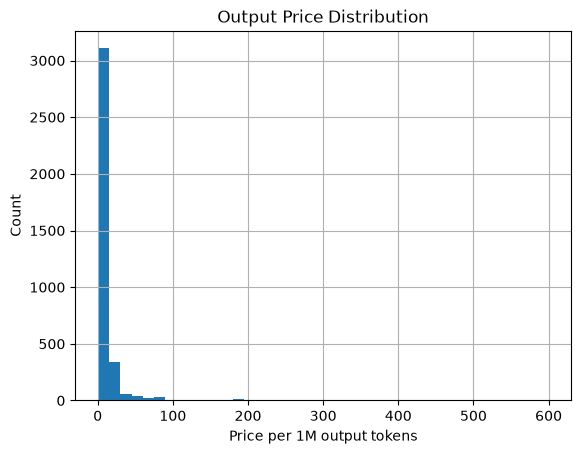

,input_price_per_1m_tokens,output_price_per_1m_tokens,cached_input_price_per_1m_tokens,batch_input_price_per_1m_tokens,batch_output_price_per_1m_tokens,price_per_image,input_price_per_second,output_price_per_second,max_input_tokens,max_output_tokens
input_price_per_1m_tokens,1.00,0.91,0.70,1.00,0.95,0.29,0.53,NaN,0.06,-0.02
output_price_per_1m_tokens,0.91,1.00,0.53,0.95,1.00,0.41,0.37,NaN,0.11,-0.01
cached_input_price_per_1m_tokens,0.70,0.53,1.00,0.88,0.58,0.27,NaN,NaN,-0.05,-0.06
batch_input_price_per_1m_tokens,1.00,0.95,0.88,1.00,0.95,0.45,NaN,NaN,-0.03,-0.02
batch_output_price_per_1m_tokens,0.95,1.00,0.58,0.95,1.00,0.44,NaN,NaN,-0.02,-0.02
price_per_image,0.29,0.41,0.27,0.45,0.44,1.00,NaN,NaN,-0.20,-0.07
input_price_per_second,0.53,0.37,NaN,NaN,NaN,NaN,1.00,NaN,0.49,-0.13
output_price_per_second,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.00,NaN,-0.46
max_input_tokens,0.06,0.11,-0.05,-0.03,-0.02,-0.20,0.49,NaN,1.00,0.53
max_output_tokens,-0.02,-0.01,-0.06,-0.02,-0.02,-0.07,-0.13,-0.46,0.53,1.00


In [4]:
df[target] = pd.to_numeric(df[target], errors="coerce")
display(df[target].describe())

df[target].dropna().hist(bins=40)
plt.title("Output Price Distribution")
plt.xlabel("Price per 1M output tokens")
plt.ylabel("Count")
plt.show()

num_cols = df.select_dtypes(include=np.number).columns
if len(num_cols) > 1:
    display(df[num_cols].corr(numeric_only=True).round(2))

## Cleaning

In [5]:
df = df.dropna(subset=[target]).copy()
df = df[df[target] >= 0].copy()

drop_cols = [c for c in [target, "model_id", "source_url", "deprecation_date", "first_listed_week"] if c in df.columns]
X = df.drop(columns=drop_cols)
y = df[target]

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

# Remove IQR outliers from numeric features and target.
check = X[num_cols].copy()
check[target] = y
q1 = check.quantile(0.25)
q3 = check.quantile(0.75)
iqr = q3 - q1
keep = ~((check < (q1 - 1.5 * iqr)) | (check > (q3 + 1.5 * iqr))).any(axis=1)

X = X.loc[keep].copy()
y = y.loc[keep].copy()

print("Rows after target and IQR filtering:", len(X))
print("Numeric features:", len(num_cols), "Categorical features:", len(cat_cols))

Rows after target and IQR filtering: 3019
Numeric features: 9 Categorical features: 17


## Train-Test Split — 70/20/10

In [6]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.125, random_state=RANDOM_STATE  # 0.125 * 80% = 10%
)

n = len(X)
print(f"Train: {len(X_train)} ({len(X_train)/n:.1%}) | "
      f"Test: {len(X_test)} ({len(X_test)/n:.1%}) | "
      f"Val: {len(X_val)} ({len(X_val)/n:.1%})")

Train: 2113 (70.0%) | Test: 604 (20.0%) | Val: 302 (10.0%)


## Preprocessing

In [7]:
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
prep = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

trained_models = {}
predictions = {}
test_rows = []
cv_rows = []


def evaluate(name, pipe, X_tr, y_tr):
    """5-fold CV on train + refit on full train + eval on train/val/test."""
    cv_res = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring=scoring)
    cv_mae = -cv_res["test_mae"]
    cv_rmse = -cv_res["test_rmse"]
    cv_r2 = cv_res["test_r2"]
    cv_rows.append({
        "Model": name,
        "CV_MAE_mean": cv_mae.mean(), "CV_MAE_std": cv_mae.std(),
        "CV_RMSE_mean": cv_rmse.mean(), "CV_RMSE_std": cv_rmse.std(),
        "CV_R2_mean": cv_r2.mean(), "CV_R2_std": cv_r2.std(),
    })
    print(f"{name} | CV MAE {cv_mae.mean():.4f} +- {cv_mae.std():.4f} | "
          f"CV RMSE {cv_rmse.mean():.4f} +- {cv_rmse.std():.4f} | CV R2 {cv_r2.mean():.4f} +- {cv_r2.std():.4f}")
    pipe.fit(X_tr, y_tr)
    trained_models[name] = pipe
    # Adjusted R2: p = raw input columns. (The 1,600+ one-hot columns would
    # exceed the val/test sizes and make the classic form undefined there.)
    p_raw = X_tr.shape[1]
    for split, Xs, ys in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
        pred = np.maximum(pipe.predict(Xs), 0)
        if split == "test":
            predictions[name] = pred
        r2 = r2_score(ys, pred)
        n = len(ys)
        adj = 1 - (1 - r2) * (n - 1) / (n - p_raw - 1) if (n - p_raw - 1) > 0 else float("nan")
        test_rows.append({
            "Model": name, "Split": split,
            "MAE": mean_absolute_error(ys, pred),
            "RMSE": np.sqrt(mean_squared_error(ys, pred)),
            "R2": r2,
            "AdjR2": adj,
        })
tuning_rows = []

def pick_best(family, candidates):
    """Fit each candidate on train, score val MAE, return the winner (val-selected regularization)."""
    best, best_mae = None, float("inf")
    for label, est in candidates:
        pipe = Pipeline([("prep", prep), ("model", est)])
        pipe.fit(X_train, y_train)
        mae = mean_absolute_error(y_val, np.maximum(pipe.predict(X_val), 0))
        tuning_rows.append({"Family": family, "Candidate": label, "Val_MAE": mae})
        print(f"{family} | {label}: val MAE {mae:.4f}")
        if mae < best_mae:
            best, best_mae = est, mae
    print(f"--> {family} winner: {best} (val MAE {best_mae:.4f})")
    return best

def pick_best_clf(family, candidates):
    """Fit each candidate on train tiers, score val accuracy, return the winner."""
    best, best_acc = None, -1.0
    for label, est in candidates:
        pipe = Pipeline([("prep", prep), ("model", est)])
        pipe.fit(X_train, y_train_tier)
        acc = accuracy_score(y_val_tier, pipe.predict(X_val))
        tuning_rows.append({"Family": family, "Candidate": label, "Val_Accuracy": acc})
        print(f"{family} | {label}: val acc {acc:.4f}")
        if acc > best_acc:
            best, best_acc = est, acc
    print(f"--> {family} winner: {best} (val acc {best_acc:.4f})")
    return best


## Linear Regression
L1 (Lasso) vs L2 (Ridge) penalty is checked on the validation set; the winner is refit and 5-fold CV evaluated.


In [8]:
# L1 (Lasso) vs L2 (Ridge) penalty check on the validation set; winner gets CV + full eval.
lr_candidates = (
    [(f"Ridge(a={a})", Ridge(alpha=a)) for a in [0.1, 1.0, 10.0, 100.0]]
    + [(f"Lasso(a={a})", Lasso(alpha=a, max_iter=5000)) for a in [0.001, 0.01, 0.1, 1.0]]
)
best_lr = pick_best("Linear", lr_candidates)
evaluate("Linear Regression", Pipeline([("prep", prep), ("model", best_lr)]), X_train, y_train)

Linear | Ridge(a=0.1): val MAE 0.6089
Linear | Ridge(a=1.0): val MAE 0.6433
Linear | Ridge(a=10.0): val MAE 0.7781
Linear | Ridge(a=100.0): val MAE 0.8563
Linear | Lasso(a=0.001): val MAE 0.6896
Linear | Lasso(a=0.01): val MAE 0.8348
Linear | Lasso(a=0.1): val MAE 0.9435
Linear | Lasso(a=1.0): val MAE 1.4514
--> Linear winner: Ridge(alpha=0.1) (val MAE 0.6089)
Linear Regression | CV MAE 0.7692 +- 0.0302 | CV RMSE 1.2559 +- 0.0693 | CV R2 0.9166 +- 0.0099


## KNN Regressor
k in {5, 9, 15, 25} is checked on the validation set (larger k = stronger smoothing against overfit).


In [9]:
knn_candidates = [(f"k={k}", KNeighborsRegressor(n_neighbors=k)) for k in [5, 9, 15, 25]]
best_knn = pick_best("KNN", knn_candidates)
evaluate("KNN Regressor", Pipeline([("prep", prep), ("model", best_knn)]), X_train, y_train)

KNN | k=5: val MAE 0.6861
KNN | k=9: val MAE 0.7753
KNN | k=15: val MAE 0.8791
KNN | k=25: val MAE 0.9296
--> KNN winner: KNeighborsRegressor() (val MAE 0.6861)
KNN Regressor | CV MAE 0.8818 +- 0.0363 | CV RMSE 1.5843 +- 0.0649 | CV R2 0.8676 +- 0.0116


## SVM Regressor

RBF-kernel SVR. C is the (inverse) regularization strength, checked on the validation set over {0.1, 1.0, 10.0}; smaller C = stronger regularization.


In [10]:
# SVM regression (RBF): smaller C = stronger regularization. Checked on validation.
svr_candidates = [(f"SVR(C={c})", SVR(C=c)) for c in [0.1, 1.0, 10.0]]
best_svr = pick_best("SVM", svr_candidates)
evaluate("SVM Regressor", Pipeline([("prep", prep), ("model", best_svr)]), X_train, y_train)

SVM | SVR(C=0.1): val MAE 1.1749
SVM | SVR(C=1.0): val MAE 0.5836
SVM | SVR(C=10.0): val MAE 0.4423
--> SVM winner: SVR(C=10.0) (val MAE 0.4423)
SVM Regressor | CV MAE 0.5817 +- 0.0170 | CV RMSE 1.0959 +- 0.0972 | CV R2 0.9366 +- 0.0092


## Artificial Neural Network
L2 penalty alpha in {1e-4, 1e-3, 1e-2} is checked on the validation set. This is the slowest cell.


In [11]:
ANN_TARGET_PARAMS = 12_000_000
probe = prep.fit_transform(X_train)
n_features = probe.shape[1]
hidden_units = max(1, int(ANN_TARGET_PARAMS / (n_features + 2)))
param_count = (n_features + 1) * hidden_units + (hidden_units + 1)
print("ANN input features:", n_features)
print("ANN hidden units:", hidden_units)
print("ANN trainable parameters:", param_count)
assert 10_000_000 <= param_count <= 14_000_000, "ANN size out of 10-14M band"

# L2 penalty (alpha) check on validation. SLOWEST cell: 3 val fits + 5 CV fits + final fit.
ann_candidates = [
    (f"ANN(alpha={a})", MLPRegressor(
        hidden_layer_sizes=(hidden_units,), max_iter=200,
        early_stopping=True, n_iter_no_change=10,
        alpha=a, random_state=RANDOM_STATE, verbose=True,
    ))
    for a in [0.0001, 0.001, 0.01]
]
best_ann = pick_best("ANN", ann_candidates)
evaluate("Artificial Neural Network", Pipeline([("prep", prep), ("model", best_ann)]), X_train, y_train)

ANN input features: 1524
ANN hidden units: 7863
ANN trainable parameters: 11998939
Iteration 1, loss = 7.43253135
Validation score: 0.654637
Iteration 2, loss = 2.74850064
Validation score: 0.804540
Iteration 3, loss = 1.48729133
Validation score: 0.847047
Iteration 4, loss = 0.96953342
Validation score: 0.887617
Iteration 5, loss = 0.66951112
Validation score: 0.908639
Iteration 6, loss = 0.45474525
Validation score: 0.923224
Iteration 7, loss = 0.33228757
Validation score: 0.928642
Iteration 8, loss = 0.24415477
Validation score: 0.934844
Iteration 9, loss = 0.18417177
Validation score: 0.939022
Iteration 10, loss = 0.14936678
Validation score: 0.937715
Iteration 11, loss = 0.11730684
Validation score: 0.940346
Iteration 12, loss = 0.09237170
Validation score: 0.940496
Iteration 13, loss = 0.08755420
Validation score: 0.942210
Iteration 14, loss = 0.07223013
Validation score: 0.941699
Iteration 15, loss = 0.05618288
Validation score: 0.942209
Iteration 16, loss = 0.04611042
Validatio

## Evaluation Metrics
The verdict is computed at runtime: best **test AdjR²** (tie-break: test MAE), plus a test-minus-train MAE overfit-gap table.


,Model,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_R2_std
2,SVM Regressor,0.5817,0.0170,1.0959,0.0972,0.9366,0.0092
3,Artificial Neural Network,0.5909,0.0415,1.0388,0.0660,0.9429,0.0075
0,Linear Regression,0.7692,0.0302,1.2559,0.0693,0.9166,0.0099
1,KNN Regressor,0.8818,0.0363,1.5843,0.0649,0.8676,0.0116


MAE                    RMSE                  \
Split                        test   train     val    test   train     val   
Model                                                                       
Artificial Neural Network  0.4444  0.1164  0.4505  0.8521  0.3339  0.9617   
KNN Regressor              0.7343  0.6002  0.6861  1.3607  1.1268  1.3359   
Linear Regression          0.6195  0.1886  0.6089  1.1224  0.3730  1.1493   
SVM Regressor              0.4241  0.2048  0.4423  0.8088  0.6395  0.9831   

                               R2                   AdjR2                  
Split                        test   train     val    test   train     val  
Model                                                                      
Artificial Neural Network  0.9597  0.9942  0.9418  0.9579  0.9941  0.9363  
KNN Regressor              0.8974  0.9334  0.8877  0.8927  0.9326  0.8771  
Linear Regression          0.9302  0.9927  0.9169  0.9270  0.9926  0.9090  
SVM Regressor              0.9637  0.9786  0.9392  0.9621  0.9783  0.9334

Best regressor by test MAE: SVM Regressor
Regularization screening (validation-selected):


,Family,Candidate,Val_MAE
0,Linear,Ridge(a=0.1),0.6089
1,Linear,Ridge(a=1.0),0.6433
2,Linear,Ridge(a=10.0),0.7781
3,Linear,Ridge(a=100.0),0.8563
4,Linear,Lasso(a=0.001),0.6896
5,Linear,Lasso(a=0.01),0.8348
6,Linear,Lasso(a=0.1),0.9435
7,Linear,Lasso(a=1.0),1.4514
8,KNN,k=5,0.6861
9,KNN,k=9,0.7753


Split,test,train,val,OverfitGap_test-minus-train
Model,,,,
Artificial Neural Network,0.4444,0.1164,0.4505,0.3280
KNN Regressor,0.7343,0.6002,0.6861,0.1341
Linear Regression,0.6195,0.1886,0.6089,0.4309
SVM Regressor,0.4241,0.2048,0.4423,0.2193


,Model,MAE,RMSE,R2,AdjR2
8,SVM Regressor,0.4241,0.8088,0.9637,0.9621
11,Artificial Neural Network,0.4444,0.8521,0.9597,0.9579
2,Linear Regression,0.6195,1.1224,0.9302,0.9270
5,KNN Regressor,0.7343,1.3607,0.8974,0.8927


VERDICT: SVM Regressor wins (test AdjR2=0.9621, MAE=0.4241).


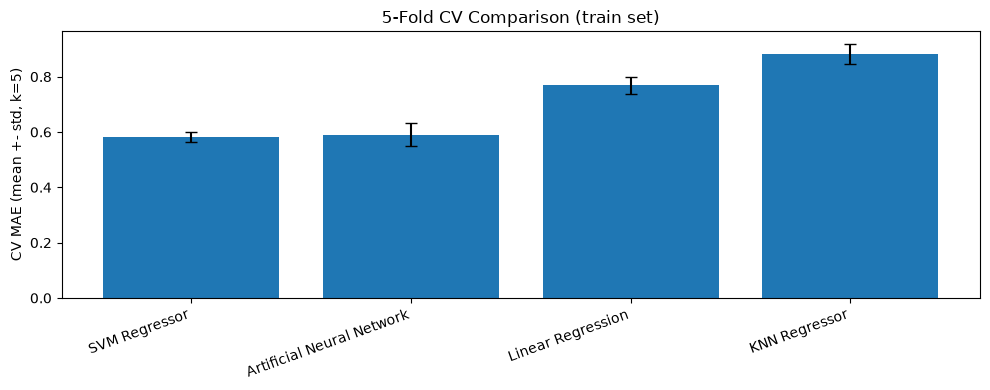

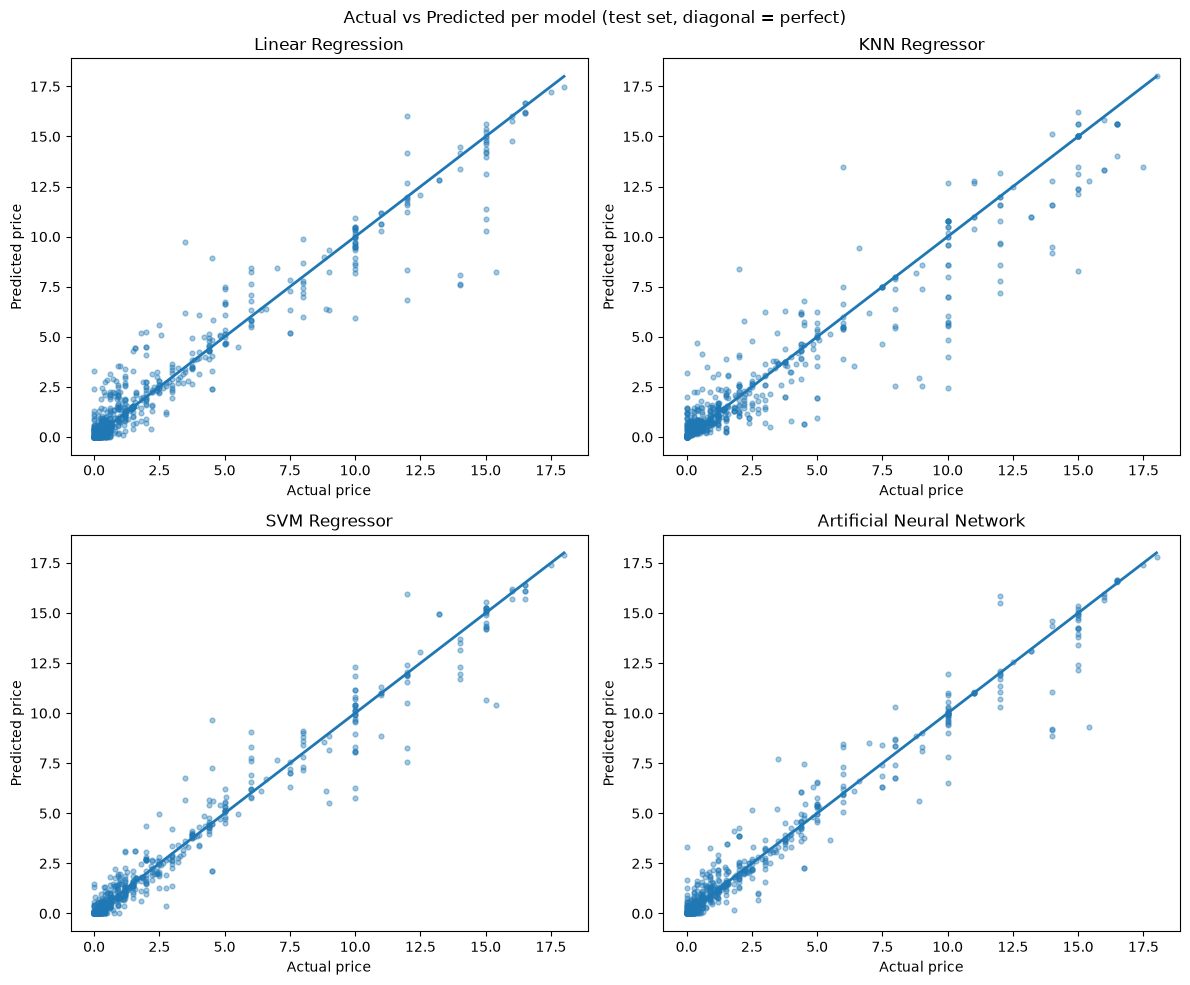

In [ ]:
cv_scores = pd.DataFrame(cv_rows).sort_values("CV_MAE_mean")
display(cv_scores.round(4))

test_scores = pd.DataFrame(test_rows)
display(test_scores.pivot(index="Model", columns="Split", values=["MAE", "RMSE", "R2", "AdjR2"]).round(4))

best_name = test_scores[test_scores["Split"] == "test"].sort_values("MAE").iloc[0]["Model"]
print("Best regressor by test MAE:", best_name)

print("Regularization screening (validation-selected):")
display(pd.DataFrame(tuning_rows).round(4))


# VERDICT: best test AdjR2, tie-break on test MAE.
tst = test_scores[test_scores["Split"] == "test"].sort_values(["AdjR2", "MAE"], ascending=[False, True])
display(tst[["Model", "MAE", "RMSE", "R2", "AdjR2"]].round(4))
v = tst.iloc[0]
print(f"VERDICT: {v['Model']} wins (test AdjR2={v['AdjR2']:.4f}, MAE={v['MAE']:.4f}).")

# CV MAE means with std bars.
order = cv_scores["Model"].tolist()
plt.figure(figsize=(10, 4))
plt.bar(cv_scores["Model"], cv_scores["CV_MAE_mean"], yerr=cv_scores["CV_MAE_std"], capsize=4)
plt.ylabel("CV MAE (mean +- std, k=5)")
plt.xticks(rotation=20, ha="right")
plt.title("5-Fold CV Comparison (train set)")
plt.tight_layout()
plt.show()

# Actual vs Predicted on the test set, one panel per model (diagonal = perfect).
names = list(predictions.keys())
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()
lo = float(min(y_test.min(), min(p.min() for p in predictions.values())))
hi = float(max(y_test.max(), max(p.max() for p in predictions.values())))
for ax, name in zip(axes, names):
    p = predictions[name]
    ax.scatter(y_test, p, alpha=0.4, s=12)
    ax.plot([lo, hi], [lo, hi], linewidth=2)  # y=x ideal line
    ax.set_xlabel("Actual price")
    ax.set_ylabel("Predicted price")
    ax.set_title(name)
fig.suptitle("Actual vs Predicted per model (test set, diagonal = perfect)")
plt.tight_layout()
plt.show()

## Price-Tier Classification — Logistic Regression vs Random Forest

Regression price is binned into 3 tiers from **train-only** quantiles (no leakage): Budget / Standard / Premium. L2-regularized Logistic Regression vs depth/leaf-limited Random Forest, validated then judged on the test split with confusion matrices (matplotlib) + classification reports.


Tier cutoffs from train: Budget <= 0.50 < Standard <= 2.50 < Premium
                            train_tiers
output_price_per_1m_tokens             
Budget                              727
Standard                            699
Premium                             687
LogReg | LogReg(C=0.1): val acc 0.8477
LogReg | LogReg(C=1.0): val acc 0.8907
LogReg | LogReg(C=10.0): val acc 0.9007
--> LogReg winner: LogisticRegression(C=10.0, max_iter=2000) (val acc 0.9007)
RF-Clf | RF(d=None/leaf=1): val acc 0.8974
RF-Clf | RF(d=12/leaf=5): val acc 0.7119
RF-Clf | RF(d=20/leaf=2): val acc 0.8344
--> RF-Clf winner: RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42) (val acc 0.8974)
===== Logistic Regression (acc=0.894) =====
              precision    recall  f1-score   support

      Budget       0.88      0.91      0.90       208
     Premium       0.95      0.93      0.94       191
    Standard       0.85      0.84      0.85       205

    accuracy                           0.89

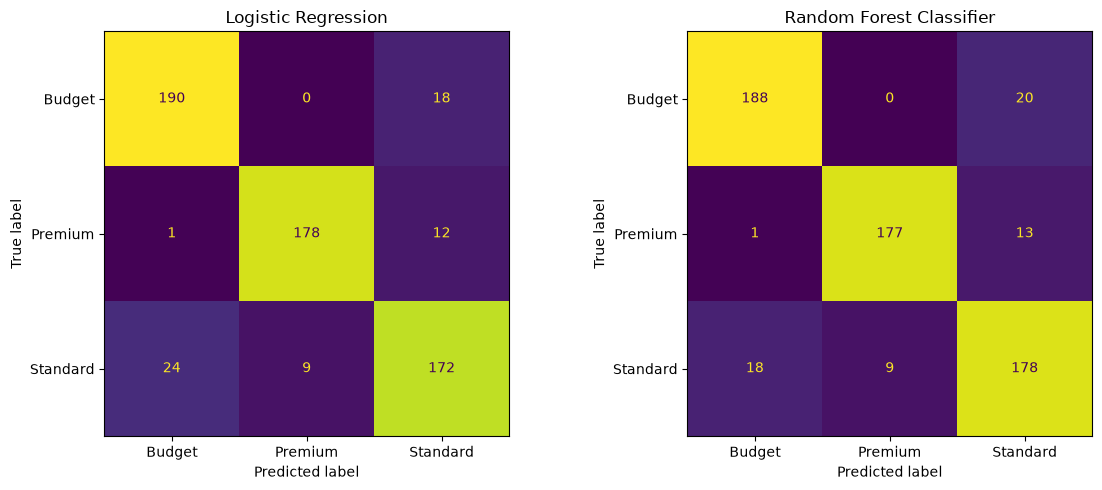

,Model,Accuracy
1,Random Forest Classifier,0.899007
0,Logistic Regression,0.894040


In [13]:
q_low, q_high = y_train.quantile(1/3), y_train.quantile(2/3)
print(f"Tier cutoffs from train: Budget <= {q_low:.2f} < Standard <= {q_high:.2f} < Premium")

def to_tier(s):
    return pd.cut(s, bins=[-float("inf"), q_low, q_high, float("inf")],
                  labels=["Budget", "Standard", "Premium"])

y_train_tier = to_tier(y_train)
y_val_tier = to_tier(y_val)
y_test_tier = to_tier(y_test)
print(y_train_tier.value_counts().to_frame("train_tiers"))

# L2-regularized Logistic Regression (C = inverse strength) vs depth/leaf-limited Random Forest.
best_logreg = pick_best_clf("LogReg", [
    (f"LogReg(C={c})", LogisticRegression(C=c, max_iter=2000)) for c in [0.1, 1.0, 10.0]
])
best_rfclf = pick_best_clf("RF-Clf", [
    (f"RF(d={d}/leaf={m})", RandomForestClassifier(n_estimators=200, max_depth=d, min_samples_leaf=m, random_state=RANDOM_STATE, n_jobs=-1))
    for d, m in [(None, 1), (12, 5), (20, 2)]
])

classifiers = {
    "Logistic Regression": best_logreg,
    "Random Forest Classifier": best_rfclf,
}

trained_clf = {}
clf_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, clf) in zip(axes, classifiers.items()):
    pipe = Pipeline([("prep", prep), ("model", clf)])
    pipe.fit(X_train, y_train_tier)
    pred = pipe.predict(X_test)
    trained_clf[name] = pipe
    acc = accuracy_score(y_test_tier, pred)
    clf_rows.append({"Model": name, "Accuracy": acc})
    print(f"===== {name} (acc={acc:.3f}) =====")
    print(classification_report(y_test_tier, pred))
    ConfusionMatrixDisplay.from_predictions(y_test_tier, pred, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

clf_scores = pd.DataFrame(clf_rows).sort_values("Accuracy", ascending=False)
display(clf_scores)

## 12. Save Artifacts

In [14]:
# Save ONLY the two winners: best regressor + best classifier.
best_clf_name = clf_scores.sort_values("Accuracy", ascending=False).iloc[0]["Model"]
with open("best_regression_model.pkl", "wb") as f:
    pickle.dump(trained_models[best_name], f)
with open("best_classification_model.pkl", "wb") as f:
    pickle.dump(trained_clf[best_clf_name], f)
print(f"Saved best_regression_model.pkl ({best_name}) and best_classification_model.pkl ({best_clf_name})")


Saved best_regression_model.pkl (SVM Regressor) and best_classification_model.pkl (Random Forest Classifier)
